# Phân tích phiên MMPP qua 8 lần chạy

Notebook chỉ đọc dữ liệu thực tế trong `results/mmpp/run_01` đến `run_08`. Số phiên được gom theo các khoảng 10 giây và quy đổi thành phiên/giây. Tám run được đặt nối tiếp trên một trục thời gian tích lũy; mỗi run được vẽ như một đoạn độc lập để không nội suy qua ranh giới.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

BIN_SEC = 10.0
RUN_IDS = [f"run_{i:02d}" for i in range(1, 9)]

# Hoạt động khi kernel được mở từ thư mục gốc repository hoặc từ notebooks/dataset/.
ROOT_CANDIDATES = [Path("../../dataset/raw/mmpp"), Path("dataset/raw/mmpp")]
RESULTS_DIR = next((p for p in ROOT_CANDIDATES if p.is_dir()), None)
if RESULTS_DIR is None:
    tried = ", ".join(str(p.resolve()) for p in ROOT_CANDIDATES)
    raise FileNotFoundError(f"Không tìm thấy thư mục dữ liệu MMPP. Đã thử: {tried}")

print(f"Đọc dữ liệu từ: {RESULTS_DIR.resolve()}")

Đọc dữ liệu từ: F:\0. UIT\KLTN\thesis-gnn-rl-autoscaling\math-load-testing\results\mmpp


In [2]:
def read_run_duration(run_dir: Path) -> float:
    """Đọc thời lượng run từ metadata; không suy ra từ arrival cuối cùng."""
    trace_meta_path = run_dir / "trace_meta.json"
    meta_path = run_dir / "meta.json"

    if trace_meta_path.is_file():
        duration = json.loads(trace_meta_path.read_text(encoding="utf-8"))["duration"]
    elif meta_path.is_file():
        duration = json.loads(meta_path.read_text(encoding="utf-8"))["duration_sec"]
    else:
        raise FileNotFoundError(
            f"{run_dir}: thiếu trace_meta.json và meta.json để xác định thời lượng chính xác"
        )

    duration = float(duration)
    if not np.isfinite(duration) or duration <= 0:
        raise ValueError(f"{run_dir}: thời lượng không hợp lệ: {duration}")
    return duration


run_series = []
summary_rows = []
cumulative_sec = 0.0

for run_id in RUN_IDS:
    run_dir = RESULTS_DIR / run_id
    trace_path = run_dir / "arrival_trace.csv"
    if not trace_path.is_file():
        raise FileNotFoundError(f"Thiếu dữ liệu đầu vào: {trace_path}")

    duration_sec = read_run_duration(run_dir)
    trace = pd.read_csv(trace_path)
    required_columns = {"t", "kind"}
    missing = required_columns.difference(trace.columns)
    if missing:
        raise ValueError(f"{trace_path}: thiếu cột {sorted(missing)}")

    sessions = trace.loc[trace["kind"].eq("session"), ["t"]].copy()
    sessions["t"] = pd.to_numeric(sessions["t"], errors="raise")
    invalid = sessions.loc[(sessions["t"] < 0) | (sessions["t"] >= duration_sec)]
    if not invalid.empty:
        raise ValueError(
            f"{trace_path}: có {len(invalid)} phiên nằm ngoài [0, {duration_sec})"
        )

    # Giữ bin cuối ngắn hơn 10 giây nếu thời lượng run không chia hết cho BIN_SEC.
    local_edges = np.arange(0.0, duration_sec, BIN_SEC)
    local_edges = np.append(local_edges, duration_sec)
    counts, _ = np.histogram(sessions["t"].to_numpy(), bins=local_edges)
    bin_widths = np.diff(local_edges)
    rates = counts / bin_widths
    cumulative_edges_min = (cumulative_sec + local_edges) / 60.0

    run_series.append({
        "run_id": run_id,
        "duration_sec": duration_sec,
        "edges_min": cumulative_edges_min,
        "counts": counts,
        "rates": rates,
        "start_min": cumulative_sec / 60.0,
        "end_min": (cumulative_sec + duration_sec) / 60.0,
    })
    summary_rows.append({
        "Run": run_id,
        "Thời lượng (phút)": duration_sec / 60.0,
        "Tổng số phiên": int(counts.sum()),
        "Phiên/giây trung bình": counts.sum() / duration_sec,
        "Phiên/giây cực đại (bin 10 giây)": float(rates.max()) if len(rates) else 0.0,
    })
    cumulative_sec += duration_sec

summary = pd.DataFrame(summary_rows)
total_minutes = cumulative_sec / 60.0
print(f"Đã đọc {len(run_series)} run; tổng thời lượng: {total_minutes:.2f} phút")

Đã đọc 8 run; tổng thời lượng: 240.00 phút


## Biểu đồ phiên/giây trên thời gian tích lũy

Mỗi đoạn màu là một run độc lập. Các đường dọc nét đứt đánh dấu ranh giới; `stairs` giữ nguyên giá trị của từng bin và không nối dữ liệu qua ranh giới run.

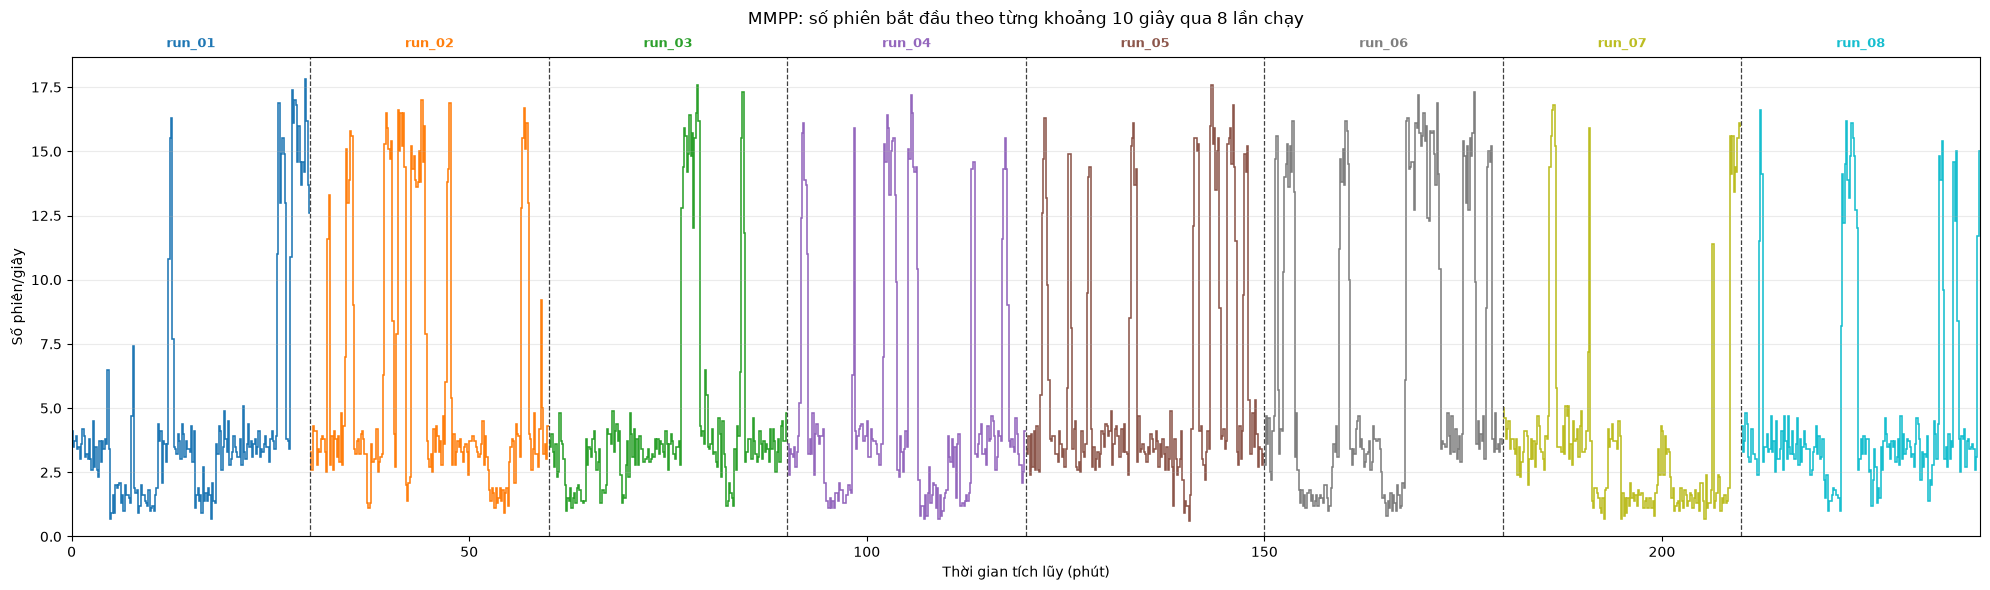

In [3]:
fig, ax = plt.subplots(figsize=(20, 6))
colors = plt.cm.tab10(np.linspace(0, 1, len(run_series)))

for idx, (item, color) in enumerate(zip(run_series, colors)):
    ax.stairs(
        item["rates"],
        item["edges_min"],
        baseline=None,
        color=color,
        linewidth=1.15,
    )
    midpoint = (item["start_min"] + item["end_min"]) / 2.0
    ax.text(
        midpoint, 1.015, item["run_id"],
        transform=ax.get_xaxis_transform(),
        ha="center", va="bottom", fontsize=9, fontweight="bold", color=color,
        clip_on=False,
    )
    if idx > 0:
        ax.axvline(item["start_min"], color="0.25", linestyle="--", linewidth=0.9)

ax.set_xlim(0, total_minutes)
ax.set_ylim(bottom=0)
ax.set_xlabel("Thời gian tích lũy (phút)")
ax.set_ylabel("Số phiên/giây")
ax.set_title("MMPP: số phiên bắt đầu theo từng khoảng 10 giây qua 8 lần chạy", pad=24)
ax.grid(axis="y", alpha=0.25)
ax.margins(x=0)
fig.tight_layout()
plt.show()

## Thống kê theo từng lần chạy

In [4]:
display(
    summary.style.format({
        "Thời lượng (phút)": "{:.2f}",
        "Tổng số phiên": "{:,.0f}",
        "Phiên/giây trung bình": "{:.3f}",
        "Phiên/giây cực đại (bin 10 giây)": "{:.3f}",
    })
)

,Run,Thời lượng (phút),Tổng số phiên,Phiên/giây trung bình,Phiên/giây cực đại (bin 10 giây)
0,run_01,30.00,"8,256",4.587,17.800
1,run_02,30.00,"10,652",5.918,17.000
2,run_03,30.00,"7,774",4.319,17.600
3,run_04,30.00,"8,887",4.937,17.200
4,run_05,30.00,"10,476",5.820,17.600
5,run_06,30.00,"12,274",6.819,17.300
6,run_07,30.00,"6,643",3.691,16.800
7,run_08,30.00,"8,466",4.703,16.600
